In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [3]:
DATA = Path("Accidents.csv") # type your full filepath
df = pd.read_csv(DATA)
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-2047758,Source2,2,2019-06-12 10:10:56,2019-06-12 10:55:58,30.641211,-91.153481,NaN,NaN,0.000,...,False,False,False,False,True,False,Day,Day,Day,Day
1,A-4694324,Source1,2,2022-12-03 23:37:14.000000000,2022-12-04 01:56:53.000000000,38.990562,-77.399070,38.990037,-77.398282,0.056,...,False,False,False,False,False,False,Night,Night,Night,Night
2,A-5006183,Source1,2,2022-08-20 13:13:00.000000000,2022-08-20 15:22:45.000000000,34.661189,-120.492822,34.661189,-120.492442,0.022,...,False,False,False,False,True,False,Day,Day,Day,Day
3,A-4237356,Source1,2,2022-02-21 17:43:04,2022-02-21 19:43:23,43.680592,-92.993317,43.680574,-92.972223,1.054,...,False,False,False,False,False,False,Day,Day,Day,Day
4,A-6690583,Source1,2,2020-12-04 01:46:00,2020-12-04 04:13:09,35.395484,-118.985176,35.395476,-118.985995,0.046,...,False,False,False,False,False,False,Night,Night,Night,Night


In [4]:
# === Data Cleaning === 
df_clean = df.drop(columns=["End_Lat", "End_Lng", "Wind_Chill(F)", "Precipitation(in)"])
df_clean = df_clean.dropna()
df_clean.duplicated().sum()

np.int64(0)

In [5]:
# Cleaned Dataset
df_clean.info()
df_clean.describe()

<class 'pandas.DataFrame'>
Index: 456181 entries, 0 to 499999
Data columns (total 42 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     456181 non-null  str    
 1   Source                 456181 non-null  str    
 2   Severity               456181 non-null  int64  
 3   Start_Time             456181 non-null  str    
 4   End_Time               456181 non-null  str    
 5   Start_Lat              456181 non-null  float64
 6   Start_Lng              456181 non-null  float64
 7   Distance(mi)           456181 non-null  float64
 8   Description            456181 non-null  str    
 9   Street                 456181 non-null  str    
 10  City                   456181 non-null  str    
 11  County                 456181 non-null  str    
 12  State                  456181 non-null  str    
 13  Zipcode                456181 non-null  str    
 14  Country                456181 non-null  str    
 15 

,Severity,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph)
count,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000
mean,2.203327,36.189211,-94.604880,0.572737,61.849253,64.421427,29.511263,9.107437,7.686465
std,0.479828,5.116876,17.315364,1.775159,19.025493,22.770062,1.017821,2.647917,5.424911
min,1.000000,24.562117,-124.497420,0.000000,-29.000000,1.000000,19.360000,0.000000,0.000000
25%,2.000000,33.335219,-117.165276,0.000000,49.000000,48.000000,29.330000,10.000000,4.600000
50%,2.000000,35.824685,-87.700971,0.037000,64.000000,67.000000,29.830000,10.000000,7.000000
75%,2.000000,40.115257,-80.375587,0.480000,76.000000,84.000000,30.020000,10.000000,10.400000
max,4.000000,48.999569,-67.484130,193.479996,196.000000,100.000000,38.440000,100.000000,822.800000


In [6]:
# === Time Patterns ===

df_clean["Start_Time"] = pd.to_datetime(df_clean["Start_Time"], format="mixed", errors="coerce")
df_clean["End_Time"] = pd.to_datetime(df_clean["End_Time"], format="mixed", errors="coerce")

# Accidents by Year
df_clean["Year"] = df_clean["Start_Time"].dt.year
by_year = df_clean["Year"].value_counts().sort_index()

# Accidents by Month
df_clean["Month"] = df_clean["Start_Time"].dt.month
by_month = df_clean["Month"].value_counts().sort_index()

# Accidents by Day
df_clean["Day"] = df_clean["Start_Time"].dt.day
by_day = df_clean["Day"].value_counts().sort_index()

# Accidents by Hour
df_clean["Hour"] = df_clean["Start_Time"].dt.hour
by_hour = df_clean["Hour"].value_counts().sort_index()


print(f"Accidents by Year:\n{by_year}\n")
print(f"Accidents by Month:\n{by_month}\n")
print(f"Accidents by Day:\n{by_day}\n")
print(f"Accidents by Hour:\n{by_hour}\n")

Accidents by Year:
Year
2016     21319
2017     37336
2018     45985
2019     57601
2020     73057
2021     97824
2022    108084
2023     14975
Name: count, dtype: int64

Accidents by Month:
Month
1     44186
2     39332
3     32555
4     35895
5     33695
6     33842
7     30138
8     34810
9     38027
10    39686
11    44079
12    49936
Name: count, dtype: int64

Accidents by Day:
Day
1     14452
2     14497
3     14500
4     14350
5     14535
6     14678
7     14564
8     14784
9     14627
10    14747
11    15453
12    15957
13    15461
14    15595
15    15671
16    15688
17    15414
18    15535
19    15554
20    15542
21    15574
22    16392
23    16685
24    14735
25    13628
26    13950
27    14345
28    14205
29    13085
30    13718
31     8260
Name: count, dtype: int64

Accidents by Hour:
Hour
0      6656
1      5617
2      5514
3      4806
4      9150
5     12915
6     22715
7     33136
8     33270
9     21086
10    20434
11    21025
12    21337
13    23736
14    27242
15    3

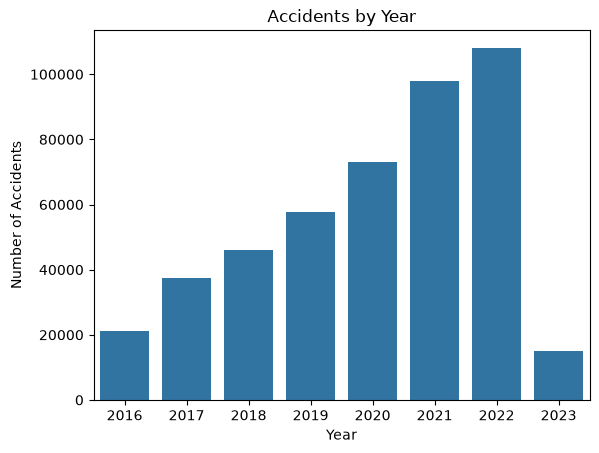

In [7]:
sns.countplot(x="Year", data=df_clean)

plt.title("Accidents by Year")
plt.xlabel("Year")
plt.ylabel("Number of Accidents")
plt.show()

In [8]:
# === Geographical Patterns ===

# df_clean["State"].value_counts().sort_index().plot(kind="bar", figsize=(12, 6))
# plt.title("Accidents by State")
# plt.xlabel("State")
# plt.ylabel("Number of Accidents")
# plt.show()
# df_clean["City"].value_counts().sort_index()
# df_clean["County"].value_counts().sort_index()
# df_clean["Timezone"].value_counts().sort_values()
df_clean["Street"].value_counts().sort_index()

Street
 1/2 Ave         1
 10 Mile Rd      1
 100th Ave N     1
 100th Ave SE    1
 100th St        1
                ..
Zorn Ave         8
Zunbar Dr        1
Zuni Rd SE       4
Zuni St          5
Zuniga Rd        1
Name: count, Length: 83288, dtype: int64

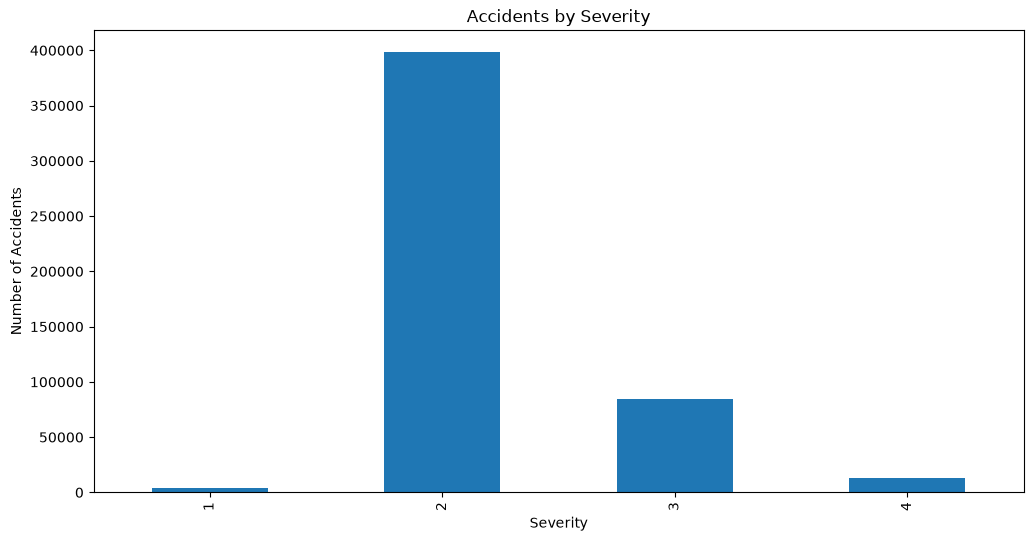

In [9]:
# === Severity Patterns ===
df["Severity"].value_counts().sort_index().plot(kind="bar", figsize=(12, 6))
plt.title("Accidents by Severity")
plt.xlabel("Severity")
plt.ylabel("Number of Accidents")
plt.show()

In [10]:
# === Weather Patterns ===

df_clean["Weather_Condition"].value_counts().sort_index()
df_clean["Temperature(F)"].value_counts().sort_index()
df_clean["Wind_Speed(mph)"].value_counts().sort_index()
df_clean["Visibility(mi)"].value_counts().sort_index()

Visibility(mi)
0.00         489
0.06          15
0.10          47
0.12         132
0.19           3
0.20         457
0.25        1714
0.38          22
0.40           3
0.50        2117
0.60           6
0.63          21
0.75        1304
0.80         433
0.88          13
0.90           1
1.00        6324
1.10           3
1.20         356
1.40           3
1.50         599
1.80         431
1.90           2
2.00        7435
2.20           4
2.50         950
2.80           7
3.00        6948
4.00        7080
4.20           2
5.00        8528
6.00        7490
7.00       12688
8.00        8763
9.00       11284
10.00     368720
10.50          1
11.00          6
12.00         22
13.00        592
15.00        368
20.00        244
23.00          1
25.00         53
30.00        165
35.00         10
40.00        110
45.00         26
50.00        130
58.00          1
60.00          8
65.00          1
70.00         11
75.00         12
76.00          2
78.00          1
80.00         21
100.00         2

In [12]:
# Cleaned Dataset
df_clean.to_csv("Accidents_cleaned.csv", index=False)

In [ ]:
unique_counts = df_clean.nunique(dropna=False)

constant_columns = unique_counts[unique_counts <= 1].index.tolist()

print("Columns that can be discarded:")
print(constant_columns)
df_clean = df_clean.drop(columns=["Country", "Turning_Loop"])
df_clean.info()

Columns that can be discarded:
['Country', 'Turning_Loop']
